# 02 · Dados de satélite: Sentinel-2, nuvens, composições, NDVI e NDRE

**AgroGeo Analytics · Projeto 01**

> ⚠️ **Modo padrão = offline com dados sintéticos.** Para usar Earth Engine real defina `AGROGEO_USE_EE=1` no `.env` e autentique (veja README). Seções que dependem do Earth Engine só executam nesse modo; as demais rodam sempre. Tudo rotulado "sintético" **não é medição**.

## Objetivos
1. Conhecer as bandas Sentinel-2 e as fórmulas de **NDVI** e **NDRE**.
2. Aplicar **máscara de nuvens (SCL)** e entender seu efeito.
3. Acessar a coleção `COPERNICUS/S2_SR_HARMONIZED` via Earth Engine.
4. Construir **composições temporais** (mensais por mediana) e visualizar lacunas.

In [1]:
import sys
from pathlib import Path
try:
    import agrogeo  # noqa: F401  (pacote instalado com `pip install -e .`)
except ModuleNotFoundError:  # kernel sem o pacote: usa o código-fonte do repositório
    _src = next(p / "src" for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "agrogeo").is_dir())
    sys.path.insert(0, str(_src))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from agrogeo import config, gis, indices, zonal, timeseries as ts_lib, maps
from agrogeo.config import DATA_SAMPLE, OUTPUTS, CRS_GEO, CRS_UTM22S

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
(OUTPUTS / "figures").mkdir(parents=True, exist_ok=True)
SYNTH_NOTE = "DADOS SINTÉTICOS — ilustrativo, não é medição"
from agrogeo.config import USE_EE
print("Modo Earth Engine:", USE_EE)

Modo Earth Engine: False


## 1. Bandas e fórmulas

| Banda | Nome | Resolução | Uso aqui |
|---|---|---|---|
| B4 | Vermelho (~665 nm) | 10 m | absorvido pela clorofila |
| B5 | Red edge 1 (~705 nm) | 20 m | sensível ao teor de clorofila |
| B8 | NIR (~842 nm) | 10 m | refletido pela estrutura foliar |
| B8A | NIR estreito (~865 nm) | 20 m | alternativa ao B8 para NDRE |
| SCL | Scene Classification | 20 m | máscara de nuvem/sombra/etc. |

$$\text{NDVI}=\frac{\rho_{NIR}-\rho_{RED}}{\rho_{NIR}+\rho_{RED}}=\frac{B8-B4}{B8+B4}\qquad
\text{NDRE}=\frac{\rho_{NIR}-\rho_{RE}}{\rho_{NIR}+\rho_{RE}}=\frac{B8-B5}{B8+B5}$$

Os valores da coleção SR estão em inteiros "escalados por 10 000": reflectância = DN / 10 000. Como o índice é uma razão, o fator de escala cancela, mas o **offset de +1000** das cenas com baseline ≥ 04.00 não cancelaria — por isso a coleção **HARMONIZED** (que remove esse deslocamento) é a indicada para séries longas.

## 2. Demonstração com pixels sintéticos

Montamos um *patch* 6×6 sintético de DN com vegetação, solo e uma nuvem; aplicamos a máscara SCL e calculamos os índices.

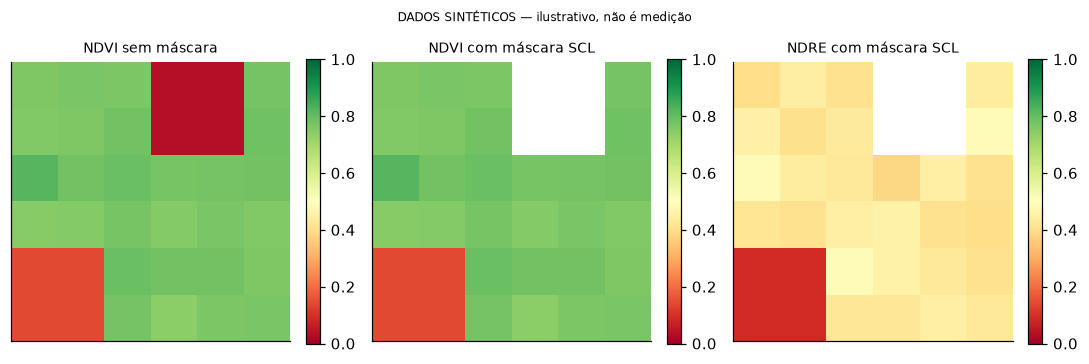

Média NDVI sem máscara: 0.619 | com máscara: 0.692


In [2]:
rng = np.random.default_rng(0)
shape = (6, 6)
# DN sintéticos (reflectância × 10000)
red = rng.normal(500, 40, shape);  nir = rng.normal(3800, 150, shape); re1 = rng.normal(1500, 80, shape)
scl = np.full(shape, 4)                   # 4 = vegetação
scl[4:, :2] = 5                           # solo exposto
red[4:, :2], nir[4:, :2], re1[4:, :2] = 1800, 2400, 2000
scl[0:2, 3:5] = 9                         # nuvem (alta prob.)
red[0:2, 3:5], nir[0:2, 3:5], re1[0:2, 3:5] = 3000, 3200, 3100

R, N, E = (indices.scale_reflectance(x) for x in (red, nir, re1))
ndvi_raw, ndre_raw = indices.ndvi(N, R), indices.ndre(N, E)
ndvi_m, ndre_m = indices.mask_invalid(ndvi_raw, scl), indices.mask_invalid(ndre_raw, scl)

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, arr, t in zip(axs, [ndvi_raw, ndvi_m, ndre_m], ["NDVI sem máscara", "NDVI com máscara SCL", "NDRE com máscara SCL"]):
    im = ax.imshow(arr, cmap="RdYlGn", vmin=0, vmax=1); ax.set_title(t, fontsize=9); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=.046)
fig.suptitle(SYNTH_NOTE, fontsize=8, y=1.0); plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "02_patch_mascara.png"); plt.show()
print(f"Média NDVI sem máscara: {np.nanmean(ndvi_raw):.3f} | com máscara: {np.nanmean(ndvi_m):.3f}")

**Como ler:** à esquerda, a nuvem produz NDVI baixo (≈ 0) que contaminaria a média; no centro, a máscara SCL a remove (cinza/NaN). Note também o solo exposto (canto inferior esquerdo) — ele **não** é removido pela SCL (classe 5 é válida), pois é uma superfície real; só o recorte por polígono do talhão (e buffer interno) controla isso.

> Limitação: a SCL erra (nuvens finas, sombras, cirrus). Por isso combinamos máscara por pixel + filtro de `CLOUDY_PIXEL_PERCENTAGE` por cena + composição por mediana.

## 3. Earth Engine: coleção filtrada e máscara

Código executado **somente** com `AGROGEO_USE_EE=1` e autenticação válida. Passos: (1) inicializar; (2) filtrar por área/datas/nuvem; (3) máscara SCL; (4) NDVI/NDRE; (5) composição mensal; (6) média por talhão (`reduceRegions`, escala 10 m).

In [3]:
from agrogeo import ee_utils
serie_ee = None
if USE_EE:
    ee = ee_utils.init_ee()
    talhoes_gdf = gpd.read_file(DATA_SAMPLE / "talhoes_sinteticos.geojson")   # troque pelo GeoJSON real
    fc = ee_utils.gdf_to_fc(talhoes_gdf)
    col = ee_utils.s2_collection(fc.geometry(), config.START_DATE, config.END_DATE, max_cloud=60)
    print("Cenas após filtro de nuvem:", col.size().getInfo())
    mensal = ee_utils.monthly_composites(col, config.START_DATE, config.END_DATE)
    serie_ee = ee_utils.zonal_timeseries(mensal, fc)
    (config.DATA_PROCESSED).mkdir(parents=True, exist_ok=True)
    serie_ee.to_csv(config.DATA_PROCESSED / "serie_s2.csv", index=False)
    print("Série Earth Engine salva:", serie_ee.shape)
else:
    print("Earth Engine desativado: seguindo com a série SINTÉTICA de data/sample/.")

Earth Engine desativado: seguindo com a série SINTÉTICA de data/sample/.


## 4. Carregando a série (real se disponível, senão sintética)

In [4]:
if serie_ee is not None:
    serie, origem = serie_ee.assign(valid_pixel_frac=np.nan), "Sentinel-2 (Earth Engine, composição mensal)"
else:
    serie = pd.read_csv(DATA_SAMPLE / "serie_sintetica_ndvi_ndre.csv", parse_dates=["date"])
    origem = "SINTÉTICA (passo de 5 dias; modelo em agrogeo.synthetic)"
print("Origem:", origem)
print(serie.shape, "| período:", serie["date"].min().date(), "→", serie["date"].max().date())
print("Fração de observações vazias (nuvem):", f"{serie['ndvi'].isna().mean():.1%}")
serie.head()

Origem: SINTÉTICA (passo de 5 dias; modelo em agrogeo.synthetic)
(3516, 6) | período: 2021-01-01 → 2024-12-31
Fração de observações vazias (nuvem): 36.1%


,date,talhao_id,ndvi,ndre,valid_pixel_frac,SINTETICO
0,2021-01-01,T01,0.811910,0.457828,0.998422,True
1,2021-01-06,T01,NaN,NaN,0.000000,True
2,2021-01-11,T01,0.817707,0.470144,0.926615,True
3,2021-01-16,T01,NaN,NaN,0.000000,True
4,2021-01-21,T01,NaN,NaN,0.000000,True


## 5. Disponibilidade de observações por mês

Em clima tropical com verão chuvoso, janeiro–março tem muito mais nuvem. O gráfico mostra a **% de observações válidas por mês do ano**.

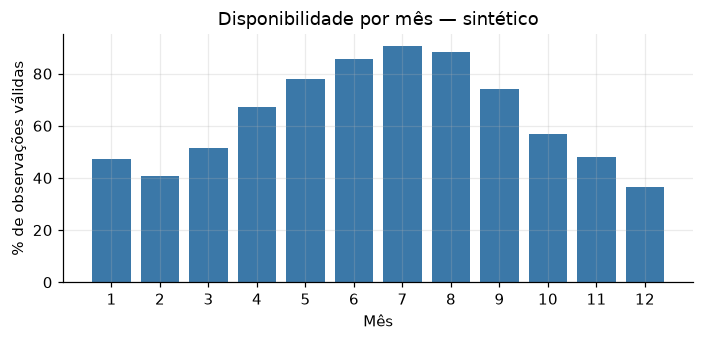

In [5]:
disp = serie.assign(mes=serie["date"].dt.month, valido=serie["ndvi"].notna()).groupby("mes")["valido"].mean() * 100
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(disp.index, disp.values, color="#3b78a8"); ax.set_xticks(range(1, 13))
ax.set(xlabel="Mês", ylabel="% de observações válidas", title="Disponibilidade por mês — " + ("sintético" if serie_ee is None else "S2"))
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "02_disponibilidade_mensal.png"); plt.show()

**Como ler:** barras baixas = muitos descartes por nuvem. Num dado sintético, o padrão vem da probabilidade de nuvem que *nós definimos* (verão chuvoso); em dados reais, confira o mesmo gráfico para sua região — não assuma.

## 6. Composição temporal mensal (mediana)

A mediana de várias observações no mês é robusta a valores extremos residuais. Exigimos `min_obs` observações para aceitar o mês.

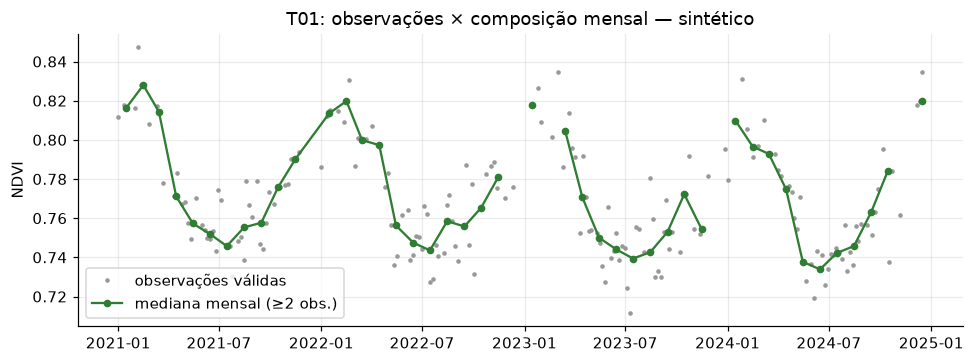

Meses sem composição válida: 4 de 47


In [6]:
tid = "T01"
bruto = serie[serie.talhao_id == tid].set_index("date")["ndvi"]
mensal_df = ts_lib.monthly_composite(serie, "ndvi", how="median", min_obs=2)
mt = mensal_df[mensal_df.talhao_id == tid].set_index("mes")["ndvi"]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(bruto.index, bruto.values, ".", color="#999", ms=4, label="observações válidas")
ax.plot(mt.index + pd.Timedelta(days=14), mt.values, "-o", color="#2e7d32", ms=4, label="mediana mensal (≥2 obs.)")
ax.set(ylabel="NDVI", title=f"{tid}: observações × composição mensal — " + ("sintético" if serie_ee is None else "S2")); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "02_composicao_mensal.png"); plt.show()
print("Meses sem composição válida:", int(mt.isna().sum()), "de", len(mt))

**Como ler:** pontos cinza são observações individuais (com lacunas por nuvem); a linha verde resume cada mês. Meses ausentes na linha são os que não atingiram o mínimo de observações.

## 7. NDVI e NDRE no tempo (um talhão)

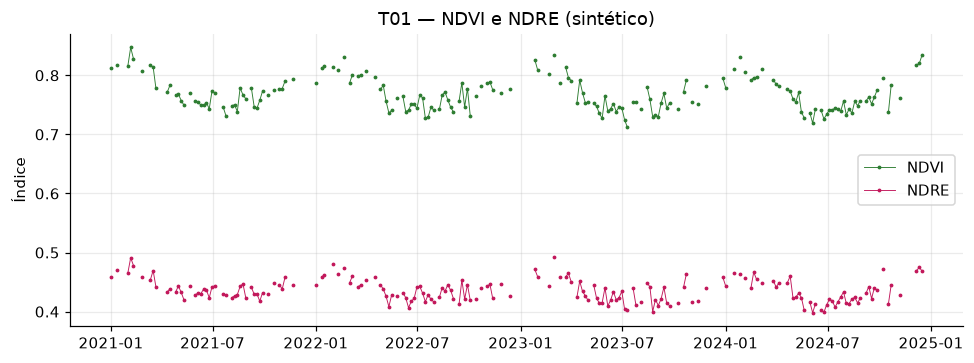

In [7]:
d = serie[serie.talhao_id == "T01"].set_index("date")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(d.index, d["ndvi"], ".-", lw=.6, ms=3, label="NDVI", color="#2e7d32")
ax.plot(d.index, d["ndre"], ".-", lw=.6, ms=3, label="NDRE", color="#c2185b")
ax.set(ylabel="Índice", title="T01 — NDVI e NDRE (" + ("sintético" if serie_ee is None else "S2") + ")"); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "02_ndvi_ndre_t01.png"); plt.show()

**Como ler:** NDRE tem amplitude e valores menores que o NDVI (usa banda de borda do vermelho). **Atenção:** na série sintética a relação NDVI→NDRE foi *imposta* pelo gerador (`ndre = 0,62·ndvi − 0,04 + ruído`); com dados reais, compare as duas curvas empiricamente e **não** reaproveite essa relação. Culturas perenes de dossel denso tendem a saturar o NDVI; NDRE é frequentemente usado por manter sensibilidade em coberturas altas — hipótese a ser verificada com seus dados.

## 8. Exercícios
1. Troque o mínimo `min_obs` de 2 para 1 e 3. O que acontece com meses de verão?
2. Em `ee_utils.mask_scl`, remova a classe 7 de `SCL_VALID`. O que muda no número de observações válidas?
3. Calcule NDRE com B8A em vez de B8 (adapte `add_indices`). Qual a implicação de B8A ter 20 m?